In [2]:
from langgraph.graph import StateGraph, START, MessagesState
from langgraph.checkpoint.memory import InMemorySaver
from dotenv import load_dotenv
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.messages import RemoveMessage

In [3]:
load_dotenv()

True

In [4]:
llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")

In [5]:
def chat(state: MessagesState):
    response = llm.invoke(state["messages"])
    return {"messages": [response]}

def delete_old_messages(state: MessagesState):
    msgs = state["messages"]

    # if more than 10 messages, delete the earliest 6
    if len(msgs) > 10:
        to_remove = msgs[:6]
        return {"messages": [RemoveMessage(id=m.id) for m in to_remove]}
    
    return {}

In [6]:
builder = StateGraph(MessagesState)

builder.add_node("chat", chat)
builder.add_node("cleanup", delete_old_messages)

builder.add_edge(START, "chat")
builder.add_edge("chat", "cleanup")      # run deletion after each response
builder.add_edge("cleanup", "__end__")

In [7]:
graph = builder.compile(checkpointer=InMemorySaver())

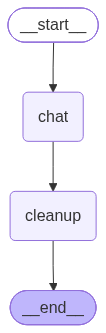

In [8]:
graph

In [9]:
CONFIG = {"configurable": {"thread_id": "t1"}}

In [10]:
# Run multiple turns
graph.invoke({"messages": [{"role": "user", "content": "Hi, I'm Saksham Agrahari."}]}, config=CONFIG)
graph.invoke({"messages": [{"role": "user", "content": "Tell me about LangGraph"}]}, config=CONFIG)
graph.invoke({"messages": [{"role": "user", "content": "Now explain checkpointers"}]}, config=CONFIG)
graph.invoke({"messages": [{"role": "user", "content": "What is Langchain?"}]}, config=CONFIG)
graph.invoke({"messages": [{"role": "user", "content": "What is System Design?"}]}, config=CONFIG)
graph.invoke({"messages": [{"role": "user", "content": "What is Gen AI?"}]}, config=CONFIG)
graph.invoke({"messages": [{"role": "user", "content": "What is my name?"}]}, config=CONFIG)

{'messages': [HumanMessage(content='What is Langchain?', additional_kwargs={}, response_metadata={}, id='f89ed880-35b0-418c-8938-0bc77cbaf5dc'),
  AIMessage(content=[{'type': 'text', 'text': '**LangChain** is an open-source framework designed to make it easier to build applications using Large Language Models (LLMs) like GPT-4, Claude, or open-source models like Llama. \n\nThink of LangChain as a **toolkit and bridge**. While LLMs are incredibly smart, they live in a "bubble"—they don\'t know your private data, they can\'t browse the live internet on their own, and they don\'t know how to talk to external databases out of the box. LangChain provides the glue to connect LLMs to the rest of the world.\n\nHere are the core components and things you can do with LangChain:\n\n### 1. The Core Modules\nLangChain is broken down into several modular pieces that you can mix and match:\n\n* **Model I/O (Prompts & LLMs):** Standardizes how you talk to LLMs. It provides tools for managing prompt te

In [11]:
snap = graph.get_state(config=CONFIG)

print("Stored messages after cleanup:", len(snap.values["messages"]))

Stored messages after cleanup: 8
